In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel('Data/Raw/sample_-_superstore.xls')

In [3]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [4]:
df.shape

(10194, 21)

In [5]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City',
       'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='str')

In [6]:
# 1.for Dataset structure
df.info()

# 2.for Statistical summary
df.describe()

# 3.for Missing values
df.isnull().sum()

# 4.for Duplicate records
df.duplicated().sum()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  str           
 2   Order Date      10194 non-null  datetime64[us]
 3   Ship Date       10194 non-null  datetime64[us]
 4   Ship Mode       10194 non-null  str           
 5   Customer ID     10194 non-null  str           
 6   Customer Name   10194 non-null  str           
 7   Segment         10194 non-null  str           
 8   Country/Region  10194 non-null  str           
 9   City            10194 non-null  str           
 10  State/Province  10194 non-null  str           
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  str           
 13  Product ID      10194 non-null  str           
 14  Category        10194 non-null  str           
 15  Sub-Category 

np.int64(0)

In [7]:
# 1. Duplicate records count
print("Duplicate Rows:", df.duplicated().sum())

# 2. Unique values in important columns
print("Categories:", df['Category'].unique())
print("Regions:", df['Region'].unique())

# 3. Numerical columns summary
df[['Sales', 'Quantity', 'Discount', 'Profit']].describe()

Duplicate Rows: 0
Categories: <StringArray>
['Office Supplies', 'Furniture', 'Technology']
Length: 3, dtype: str
Regions: <StringArray>
['Central', 'East', 'South', 'West']
Length: 4, dtype: str


,Sales,Quantity,Discount,Profit
count,10194.000000,10194.000000,10194.000000,10194.000000
mean,228.225854,3.791838,0.155385,28.673417
std,619.906839,2.228317,0.206249,232.465115
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.220000,2.000000,0.000000,1.760800
50%,53.910000,3.000000,0.200000,8.690000
75%,209.500000,5.000000,0.200000,29.297925
max,22638.480000,14.000000,0.800000,8399.976000


In [8]:
# 1. Check missing values
df.isnull().sum()

# 2. Check unique postal codes
df['Postal Code'].value_counts(dropna=False).head(10)

# 3. Check text columns for extra spaces
text_columns = df.select_dtypes(include=['str']).columns

for col in text_columns:
    print(col, ":", df[col].str.strip().ne(df[col]).sum())

# 4. Check date range
print("First Order:", df['Order Date'].min())
print("Last Order:", df['Order Date'].max())

Order ID : 0
Ship Mode : 0
Customer ID : 0
Customer Name : 0
Segment : 0
Country/Region : 0
City : 0
State/Province : 0
Region : 0
Product ID : 0
Category : 0
Sub-Category : 0
Product Name : 0
First Order: 2023-01-03 00:00:00
Last Order: 2026-12-30 00:00:00


In [9]:
# 1. Postal Code details
print("Postal Code Data Type:", df['Postal Code'].dtype)
print("Missing Postal Codes:", df['Postal Code'].isnull().sum())
print(df['Postal Code'].value_counts(dropna=False).head(10))

# 2. Future order dates
print("Future Orders:", (df['Order Date'] > pd.Timestamp.today().normalize()).sum())

# 3. Shipping date validation
print("Invalid Shipping Dates:", (df['Ship Date'] < df['Order Date']).sum())

Postal Code Data Type: object
Missing Postal Codes: 0
Postal Code
10035    263
10024    230
10009    229
94122    203
10011    193
94110    166
98105    165
19134    160
90049    151
98103    151
Name: count, dtype: int64
Future Orders: 596
Invalid Shipping Dates: 0


In [10]:
# Identify future orders
future_mask = df['Order Date'] > pd.Timestamp.today().normalize()

# Count future orders
print("Future Orders:", future_mask.sum())

# Display first 10 future records
print(
    df.loc[future_mask, [
        'Order ID',
        'Order Date',
        'Ship Date',
        'Sales',
        'Profit'
    ]].head(10)
)

print(
    df.loc[future_mask]
      .groupby(df.loc[future_mask, 'Order Date'].dt.year)
      .size()
)

print("First Future Order:", df.loc[future_mask, 'Order Date'].min())
print("Last Future Order:", df.loc[future_mask, 'Order Date'].max())

Future Orders: 596
            Order ID Order Date  Ship Date    Sales    Profit
9598  US-2026-144036 2026-11-22 2026-11-26   35.712    2.2320
9599  US-2026-103156 2026-11-23 2026-11-24   24.048    7.2144
9600  US-2026-149160 2026-11-23 2026-11-26   28.400   11.0760
9601  US-2026-119746 2026-11-23 2026-11-27    6.464   -4.0400
9602  US-2026-156622 2026-11-23 2026-11-26  127.785  -31.0335
9603  US-2026-119004 2026-11-23 2026-11-28    3.304    1.0738
9604  US-2026-149160 2026-11-23 2026-11-26  287.920  138.2016
9605  US-2026-107832 2026-11-23 2026-11-26    7.476   -5.9808
9606  US-2026-156622 2026-11-23 2026-11-26    6.104   -9.1560
9607  US-2026-119746 2026-11-23 2026-11-27   11.520    4.1760
Order Date
2026    596
dtype: int64
First Future Order: 2026-11-22 00:00:00
Last Future Order: 2026-12-30 00:00:00


In [12]:
df_clean = df.copy()

df_clean['Order Year'] = df_clean['Order Date'].dt.year

df_clean['Order Month'] = df_clean['Order Date'].dt.month

df_clean['Month Name'] = df_clean['Order Date'].dt.strftime('%B')

df_clean['Shipping Days'] = (
    df_clean['Ship Date'] - df_clean['Order Date']
).dt.days

df['Profit margin'] = df['Profit'] / df['Sales'] * 100

df_clean['Profit Status'] = np.where(
    df_clean['Profit'] > 0, 'Profitable',
    np.where(
        df_clean['Profit'] < 0, 'Loss',
        'Break-even'
    )
)
 
df_clean[[
    'Order Date',
    'Order Year',
    'Order Month',
    'Month Name',
    'Ship Date',
    'Shipping Days',
    'Profit margin',
    'Profit Status'
]].head(10)
df_clean['Profit Status'].value_counts()
df_clean[['Sales', 'Profit', 'Profit margin']].head(10)

,Sales,Profit,Profit margin
0,16.448,5.5512,33.75
1,3.540,-5.4870,-155.00
2,11.784,4.2717,36.25
3,272.736,-64.7748,-23.75
4,19.536,4.8840,25.00
5,2573.820,746.4078,29.00
6,5.480,1.4796,27.00
7,12.780,5.2398,41.00
8,609.980,274.4910,45.00
9,31.120,0.3112,1.00


In [13]:
df_clean.groupby('Category').agg({'Sales':'sum',
                                'Profit':'sum',
                                'Quantity':'sum',
                                'Discount': 'mean'})

,Sales,Profit,Quantity,Discount
Category,,,,
Furniture,754747.7613,19729.9956,8369,0.172962
Office Supplies,731893.3140,126023.4434,23268,0.156348
Technology,839893.2790,146543.3756,7017,0.131475


In [14]:
df_clean.groupby('Category')['Profit'].sum().sort_values(ascending=False)


Category
Technology         146543.3756
Office Supplies    126023.4434
Furniture           19729.9956
Name: Profit, dtype: float64

In [15]:
df_clean.groupby('Region').agg({
    'Sales':'sum',
    'Profit':'sum'
}).reset_index().nlargest(2, 'Profit')

,Region,Sales,Profit
3,West,739813.6085,110798.8170
1,East,691828.1680,94883.2603


In [16]:
df_clean.groupby('Region')['Profit'].sum().sort_values(ascending=False)

Region
West       110798.8170
East        94883.2603
South       46749.4303
Central     39865.3070
Name: Profit, dtype: float64

In [17]:
df_clean.groupby('Region').agg({
    'Sales':'sum',
    'Profit':'sum'
}).reset_index().nsmallest(2, 'Profit')

,Region,Sales,Profit
0,Central,503170.6728,39865.3070
2,South,391721.9050,46749.4303


In [18]:
df_clean['Sub-Category'].unique()

<StringArray>
[      'Paper',     'Binders',      'Labels',     'Storage',         'Art',
      'Chairs',   'Fasteners',      'Phones', 'Furnishings', 'Accessories',
   'Bookcases',   'Envelopes',  'Appliances',      'Tables',    'Supplies',
    'Machines',     'Copiers']
Length: 17, dtype: str

In [19]:
df_clean.groupby('Sub-Category')['Sales'].sum().sort_values(ascending=False).head(5)

Sub-Category
Chairs     335768.249
Phones     331842.640
Storage    224644.554
Tables     208020.182
Binders    207354.881
Name: Sales, dtype: float64

In [20]:
df_clean.groupby('Sub-Category')['Profit'].sum().sort_values(ascending=False).head(5)

Sub-Category
Copiers        56093.9365
Phones         45050.8265
Accessories    41936.6357
Paper          34511.5070
Binders        31426.1003
Name: Profit, dtype: float64

In [21]:
df_clean.groupby('Sub-Category')['Profit'].sum().sort_values(ascending=True).head(5)

Sub-Category
Tables      -17753.2061
Bookcases    -3632.0736
Supplies     -1171.3945
Fasteners     2428.6358
Machines      3461.9769
Name: Profit, dtype: float64

In [22]:
subcat_profit = df_clean.groupby('Sub-Category')['Profit'].sum()
subcat_profit

Sub-Category
Accessories    41936.6357
Appliances     18329.4844
Art             6653.1962
Binders        31426.1003
Bookcases      -3632.0736
Chairs         27223.5323
Copiers        56093.9365
Envelopes       6988.0247
Fasteners       2428.6358
Furnishings    13891.7430
Labels          5572.7780
Machines        3461.9769
Paper          34511.5070
Phones         45050.8265
Storage        21285.1115
Supplies       -1171.3945
Tables        -17753.2061
Name: Profit, dtype: float64

In [23]:
loss_category = subcat_profit[subcat_profit<0]
loss_category

Sub-Category
Bookcases    -3632.0736
Supplies     -1171.3945
Tables      -17753.2061
Name: Profit, dtype: float64

In [24]:
loss_category.loc[['Tables', 'Bookcases']]

Sub-Category
Tables      -17753.2061
Bookcases    -3632.0736
Name: Profit, dtype: float64

In [25]:
type(df_clean)

pandas.DataFrame

In [26]:
df_clean.shape

(10194, 27)

In [27]:
product_sales = df_clean.groupby('Product Name')['Sales'].sum()

product_sales.sort_values(ascending=False).head(10)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64

In [28]:
product_profit = df_clean.groupby('Product Name')['Profit'].sum()

product_profit.sort_values(ascending=False).head(10)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Canon PC1060 Personal Laser Copier                                              4570.9347
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Ativa V4110MDD Micro-Cut Shredder                                               3772.9461
3D Systems Cube Printer, 2nd Generation, Magenta                                3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System                      3696.2820
Ibico EPK-21 Electric Binding System                                            3345.2823
Zebra ZM400 Thermal Label Printer                                               3343.5360
Name: Profit, dtype: float64

In [29]:
loss_products = product_profit[product_profit<0]
loss_products.sort_values().head(15)

Product Name
Cubify CubeX 3D Printer Double Head Print                                      -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                                      -4589.9730
Cubify CubeX 3D Printer Triple Head Print                                      -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases                       -2876.1156
Bush Advantage Collection Racetrack Conference Table                           -1934.3976
GBC DocuBind P400 Electric Binding System                                      -1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit                          -1811.0784
Martin Yale Chadless Opener Electric Letter Opener                             -1299.1836
Balt Solid Wood Round Tables                                                   -1201.0581
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables              -1148.4375
Riverside Furniture Oval Coffee Table, Oval End Table, End Table with Drawer   -1147.40

In [30]:
len(loss_products)

302

In [31]:
loss_percentage = (len(loss_products) / len(product_profit)) * 100
loss_percentage

16.333153055705786

In [32]:
product_profit.sort_values(ascending=False).head(5)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Canon PC1060 Personal Laser Copier                                              4570.9347
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Name: Profit, dtype: float64

In [33]:
product_profit.sort_values().head(5)

Product Name
Cubify CubeX 3D Printer Double Head Print                  -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                  -4589.9730
Cubify CubeX 3D Printer Triple Head Print                  -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases   -2876.1156
Bush Advantage Collection Racetrack Conference Table       -1934.3976
Name: Profit, dtype: float64

In [34]:
customer_sales = df_clean.groupby('Customer Name')['Sales'].sum()
customer_sales.sort_values(ascending=False).head(10)

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64

In [35]:
customer_profit = df_clean.groupby('Customer Name')['Profit'].sum()
customer_profit.sort_values(ascending=False).head(10)

Customer Name
Tamara Chand            8981.3239
Raymond Buch            6976.0959
Sanjit Chand            5757.4119
Hunter Lopez            5622.4292
Adrian Barton           5444.8055
Tom Ashbrook            4703.7883
Christopher Martinez    3899.8904
Keith Dawkins           3038.6254
Andy Reiter             2884.6208
Daniel Raglin           2869.0760
Name: Profit, dtype: float64

In [36]:
loss_customer = customer_profit[customer_profit<0]
loss_customer.sort_values().head(10)

Customer Name
Cindy Stewart      -6626.3895
Grant Thornton     -4108.6589
Luke Foster        -3583.9770
Sharelle Roach     -3333.9144
Henry Goldwyn      -2797.9635
Nathan Cano        -2204.8072
Sean Braxton       -2082.7451
Sean Miller        -1980.7393
Christine Phan     -1850.3029
Natalie Fritzler   -1695.9714
Name: Profit, dtype: float64

In [37]:
len(customer_profit[customer_profit<0])

158

In [38]:
loss_customer_percentage = (len(customer_profit[customer_profit<0])/len(customer_profit))*100
loss_customer_percentage

19.75

In [39]:
customer_analysis = df_clean.groupby('Customer Name').agg({
    'Sales':'sum',
    'Profit':'sum'
})

customer_analysis.head()

,Sales,Profit
Customer Name,,
Aaron Bergman,886.156,129.3465
Aaron Hawkins,1744.700,365.2152
Aaron Smayling,3050.692,-253.5746
Adam Bellavance,7755.620,2054.5885
Adam Hart,3250.337,281.1890


In [40]:
customer_analysis.sort_values(by='Sales',ascending=False).head(10)

,Sales,Profit
Customer Name,,
Sean Miller,25043.050,-1980.7393
Tamara Chand,19052.218,8981.3239
Raymond Buch,15117.339,6976.0959
Tom Ashbrook,14595.620,4703.7883
Adrian Barton,14473.571,5444.8055
Ken Lonsdale,14175.229,806.8550
Sanjit Chand,14142.334,5757.4119
Hunter Lopez,12873.298,5622.4292
Sanjit Engle,12209.438,2650.6769


In [41]:
customer_analysis.sort_values(by='Profit',ascending=False).head(10)

,Sales,Profit
Customer Name,,
Tamara Chand,19052.218,8981.3239
Raymond Buch,15117.339,6976.0959
Sanjit Chand,14142.334,5757.4119
Hunter Lopez,12873.298,5622.4292
Adrian Barton,14473.571,5444.8055
Tom Ashbrook,14595.620,4703.7883
Christopher Martinez,8954.020,3899.8904
Keith Dawkins,8181.256,3038.6254
Andy Reiter,6608.448,2884.6208


In [42]:
customer_analysis.sort_values(by='Profit',ascending=True).head(10)

,Sales,Profit
Customer Name,,
Cindy Stewart,5690.055,-6626.3895
Grant Thornton,9351.212,-4108.6589
Luke Foster,3930.509,-3583.9770
Sharelle Roach,3233.481,-3333.9144
Henry Goldwyn,3247.642,-2797.9635
Nathan Cano,2218.990,-2204.8072
Sean Braxton,8057.891,-2082.7451
Sean Miller,25043.050,-1980.7393
Christine Phan,5888.275,-1850.3029


In [43]:
yearly_sales = df_clean.groupby('Order Year')['Sales'].sum()
yearly_sales

Order Year
2023    494040.2121
2024    472993.0310
2025    613933.5800
2026    745567.5312
Name: Sales, dtype: float64

In [44]:
yearly_profit = df_clean.groupby('Order Year')['Profit'].sum()
yearly_profit

Order Year
2023    51684.2957
2024    62020.9695
2025    82665.2018
2026    95926.3476
Name: Profit, dtype: float64

In [45]:
monthly_sales = df_clean.groupby('Month Name')['Sales'].sum()
monthly_sales

Month Name
April        138098.7486
August       161821.9150
December     330218.1755
February      59751.2514
January       96069.5156
July         149001.7130
June         153459.9973
March        210672.0868
May          158765.0337
November     352665.9910
October      207126.2567
September    308883.6697
Name: Sales, dtype: float64

In [46]:
monthly_profit = df_clean.groupby('Month Name')['Profit'].sum()
monthly_profit

Month Name
April        11625.5223
August       22942.4239
December     44229.8480
February     10294.6107
January       9497.2501
July         14013.5496
June         21508.2067
March        29345.0405
May          22850.0324
November     35541.2553
October      33214.5143
September    37234.5608
Name: Profit, dtype: float64

In [47]:
monthly_analysis = df_clean.groupby('Month Name').agg({
    'Sales':'sum',
    'Profit':'sum'
})
monthly_analysis

,Sales,Profit
Month Name,,
April,138098.7486,11625.5223
August,161821.9150,22942.4239
December,330218.1755,44229.8480
February,59751.2514,10294.6107
January,96069.5156,9497.2501
July,149001.7130,14013.5496
June,153459.9973,21508.2067
March,210672.0868,29345.0405
May,158765.0337,22850.0324


In [48]:
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_analysis = monthly_analysis.reindex(month_order)
monthly_analysis

,Sales,Profit
Month Name,,
January,96069.5156,9497.2501
February,59751.2514,10294.6107
March,210672.0868,29345.0405
April,138098.7486,11625.5223
May,158765.0337,22850.0324
June,153459.9973,21508.2067
July,149001.7130,14013.5496
August,161821.9150,22942.4239
September,308883.6697,37234.5608


In [49]:
monthly_analysis['Sales'].idxmax()

'November'

In [50]:
monthly_analysis['Profit'].idxmax()

'December'

In [51]:
monthly_analysis['Sales'].idxmin()

'February'

In [52]:
monthly_analysis['Profit'].idxmin()

'January'

In [53]:
yearly_analysis = df_clean.groupby('Order Year').agg({
    'Sales': 'sum',
    'Profit': 'sum'
})

yearly_analysis

,Sales,Profit
Order Year,,
2023,494040.2121,51684.2957
2024,472993.0310,62020.9695
2025,613933.5800,82665.2018
2026,745567.5312,95926.3476


In [54]:
yearly_analysis['Profit margin'] = (yearly_analysis['Profit'] / yearly_analysis['Sales'])*100
yearly_analysis['Profit margin']

Order Year
2023    10.461556
2024    13.112449
2025    13.464844
2026    12.866218
Name: Profit margin, dtype: float64

In [55]:
yearly_analysis.sort_values(by='Sales',ascending=False)

,Sales,Profit,Profit margin
Order Year,,,
2026,745567.5312,95926.3476,12.866218
2025,613933.5800,82665.2018,13.464844
2023,494040.2121,51684.2957,10.461556
2024,472993.0310,62020.9695,13.112449


In [56]:
yearly_analysis.sort_values(by='Profit',ascending=False)

,Sales,Profit,Profit margin
Order Year,,,
2026,745567.5312,95926.3476,12.866218
2025,613933.5800,82665.2018,13.464844
2024,472993.0310,62020.9695,13.112449
2023,494040.2121,51684.2957,10.461556


In [57]:
yearly_sales

Order Year
2023    494040.2121
2024    472993.0310
2025    613933.5800
2026    745567.5312
Name: Sales, dtype: float64

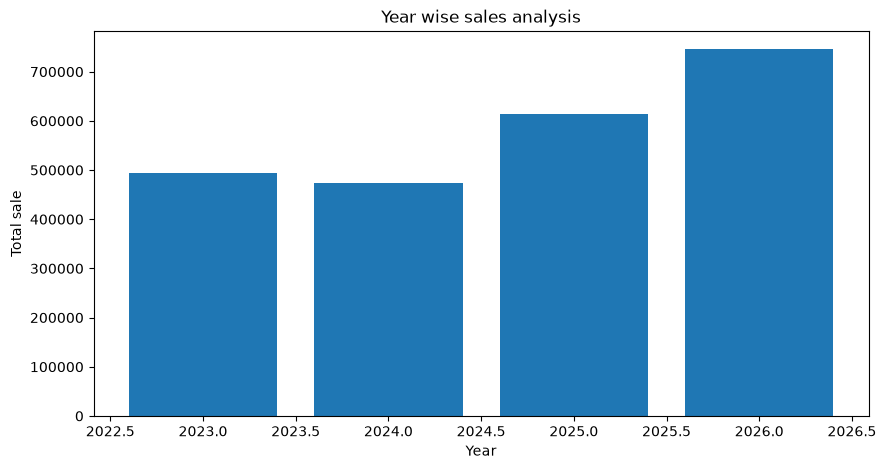

In [58]:
plt.figure(figsize=(10,5))
plt.bar(yearly_sales.index,yearly_sales.values)

plt.title('Year wise sales analysis')
plt.xlabel('Year')
plt.ylabel('Total sale')

plt.show()

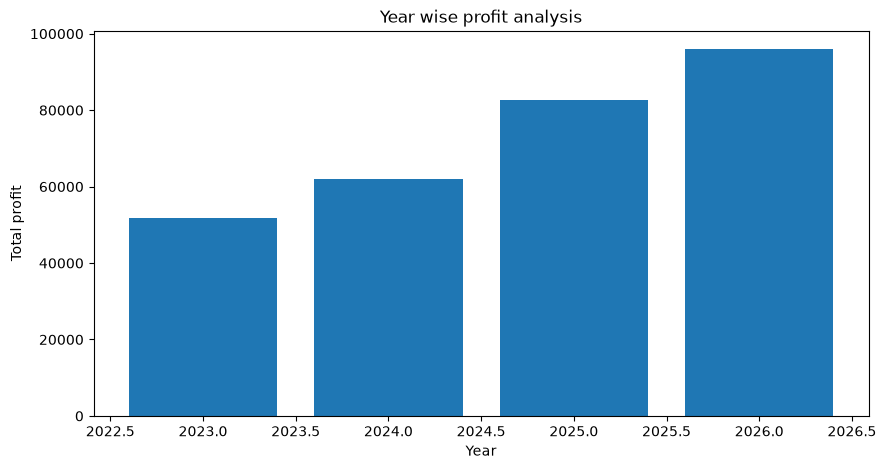

In [59]:
plt.figure(figsize=(10,5))
plt.bar(yearly_profit.index,yearly_profit.values)

plt.title('Year wise profit analysis')
plt.xlabel('Year')
plt.ylabel('Total profit')

plt.show()

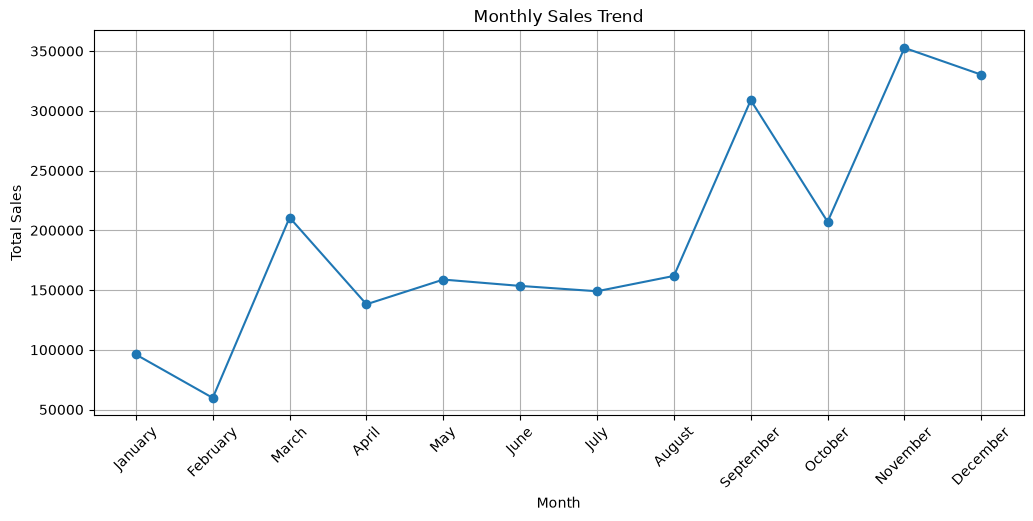

In [60]:
plt.figure(figsize=(12, 5))

plt.plot(monthly_analysis.index, monthly_analysis['Sales'], marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.grid()

plt.show()

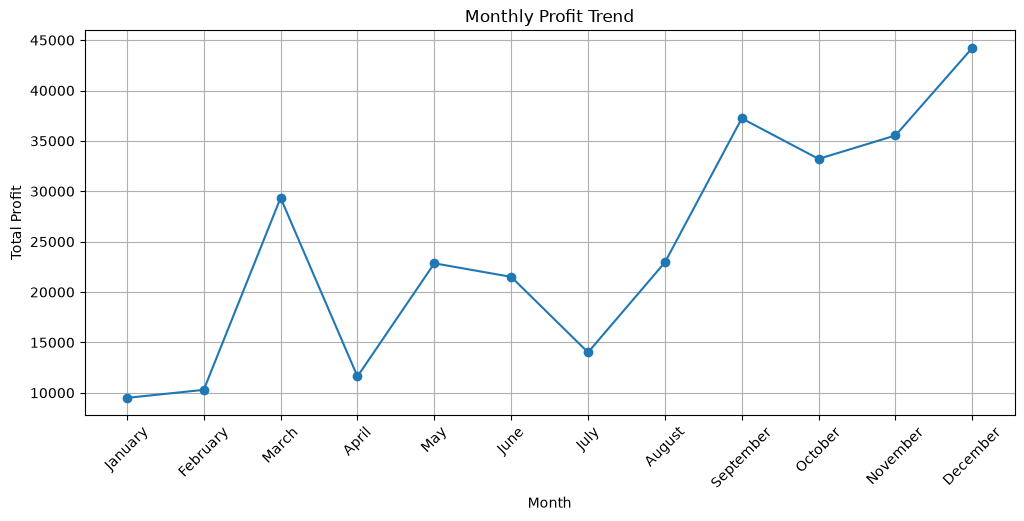

In [61]:
plt.figure(figsize=(12, 5))

plt.plot(monthly_analysis.index, monthly_analysis['Profit'], marker='o')

plt.title('Monthly Profit Trend')
plt.xlabel('Month')
plt.ylabel('Total Profit')

plt.xticks(rotation=45)
plt.grid()

plt.show()

In [62]:
category_analysis = df_clean.groupby('Category')['Sales'].sum()

category_analysis

Category
Furniture          754747.7613
Office Supplies    731893.3140
Technology         839893.2790
Name: Sales, dtype: float64

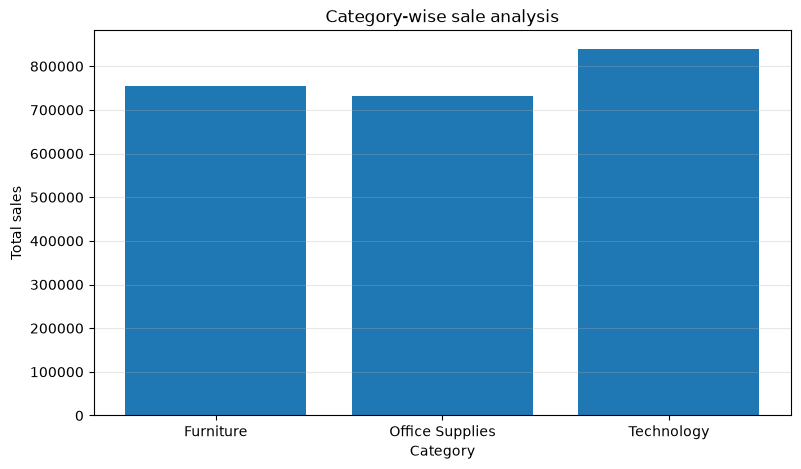

In [63]:
plt.figure(figsize=(9,5))
plt.bar(category_analysis.index,category_analysis.values)

plt.title('Category-wise sale analysis')
plt.xlabel('Category')
plt.ylabel('Total sales')

plt.grid(axis='y',alpha=0.3)
plt.show()

In [64]:
category_profit = df_clean.groupby('Category')['Profit'].sum()
category_profit

Category
Furniture           19729.9956
Office Supplies    126023.4434
Technology         146543.3756
Name: Profit, dtype: float64

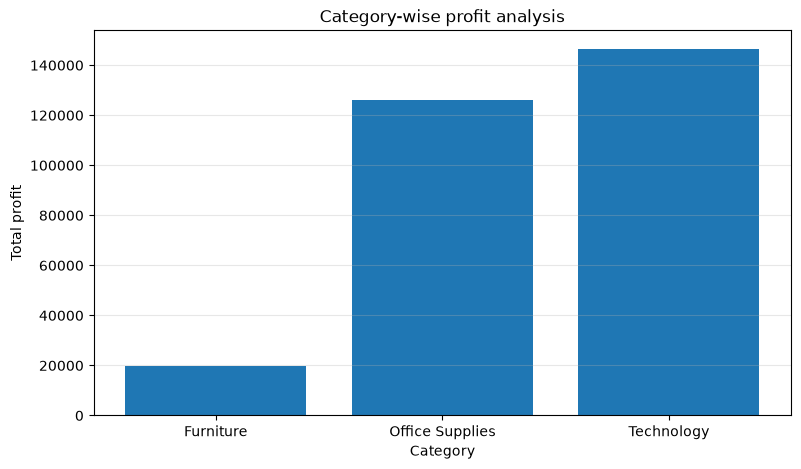

In [65]:
plt.figure(figsize=(9,5))
plt.bar(category_profit.index,category_profit.values)

plt.title('Category-wise profit analysis')
plt.xlabel('Category')
plt.ylabel('Total profit')

plt.grid(axis='y',alpha=0.3)
plt.show()

In [66]:
region_sales = df_clean.groupby('Region')['Sales'].sum()
region_sales

Region
Central    503170.6728
East       691828.1680
South      391721.9050
West       739813.6085
Name: Sales, dtype: float64

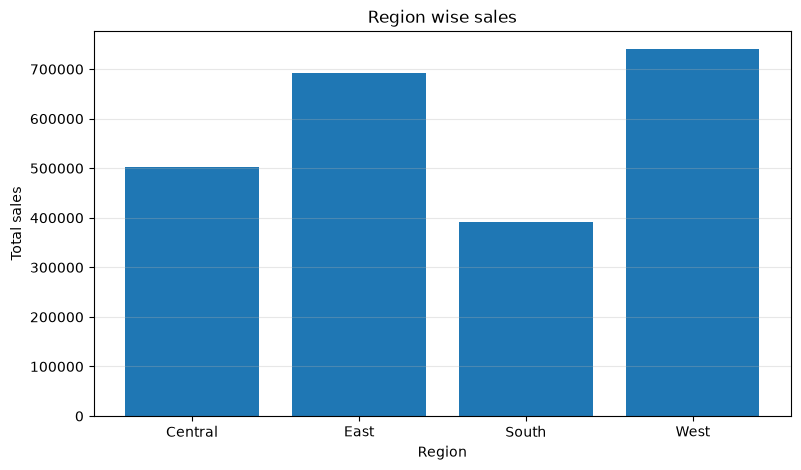

In [67]:
plt.figure(figsize=(9,5))
plt.bar(region_sales.index,region_sales.values)

plt.title('Region wise sales')
plt.xlabel('Region')
plt.ylabel('Total sales')

plt.grid(axis='y',alpha=0.3)
plt.show()

In [68]:
region_profit = df_clean.groupby('Region')['Profit'].sum()
region_profit

Region
Central     39865.3070
East        94883.2603
South       46749.4303
West       110798.8170
Name: Profit, dtype: float64

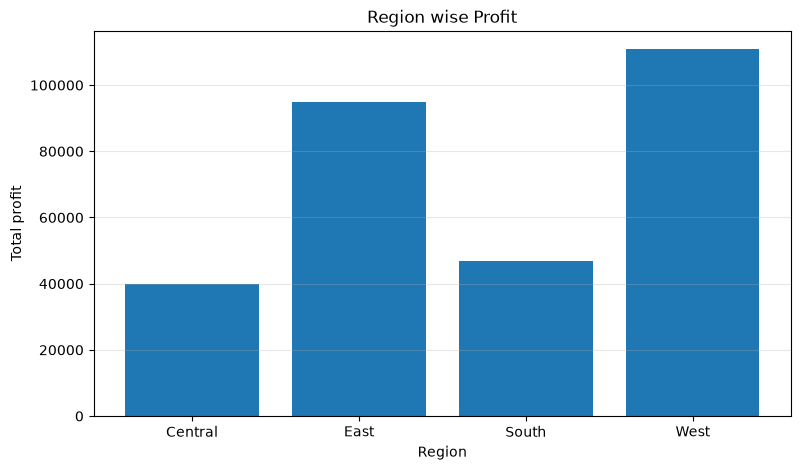

In [69]:
plt.figure(figsize=(9,5))
plt.bar(region_profit.index,region_profit.values)

plt.title('Region wise Profit')
plt.xlabel('Region')
plt.ylabel('Total profit')

plt.grid(axis='y',alpha=0.3)
plt.show()

In [ ]:
subcat_profit.head(10)

Sub-Category
Accessories    41936.6357
Appliances     18329.4844
Art             6653.1962
Binders        31426.1003
Bookcases      -3632.0736
Chairs         27223.5323
Copiers        56093.9365
Envelopes       6988.0247
Fasteners       2428.6358
Furnishings    13891.7430
Name: Profit, dtype: float64

In [70]:
top_10_subcat = subcat_profit.sort_values(ascending=False).head(10)
top_10_subcat

Sub-Category
Copiers        56093.9365
Phones         45050.8265
Accessories    41936.6357
Paper          34511.5070
Binders        31426.1003
Chairs         27223.5323
Storage        21285.1115
Appliances     18329.4844
Furnishings    13891.7430
Envelopes       6988.0247
Name: Profit, dtype: float64

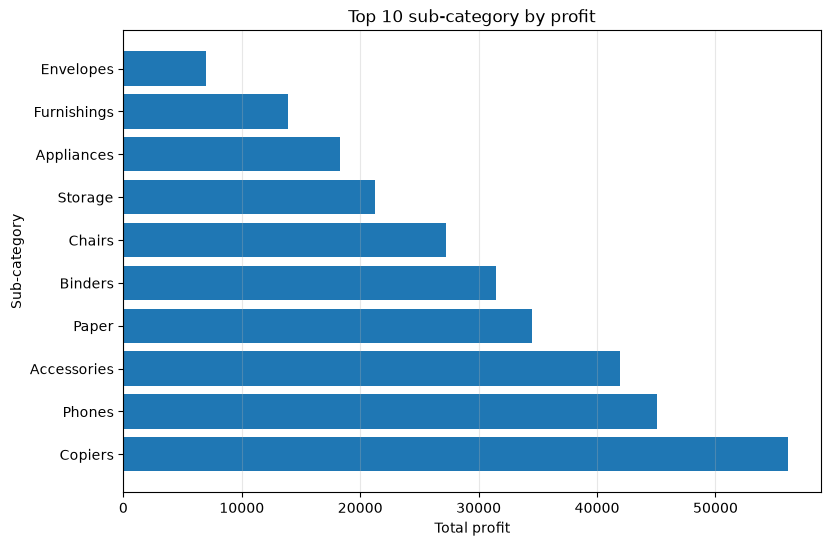

In [71]:
plt.figure(figsize=(9,6))
plt.barh(top_10_subcat.index,top_10_subcat.values)

plt.title('Top 10 sub-category by profit')
plt.xlabel('Total profit')
plt.ylabel('Sub-category')

plt.grid(axis='x',alpha=0.3)
plt.show()

In [72]:
top_10_products = product_sales.sort_values(ascending=False).head(10)
top_10_products

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64

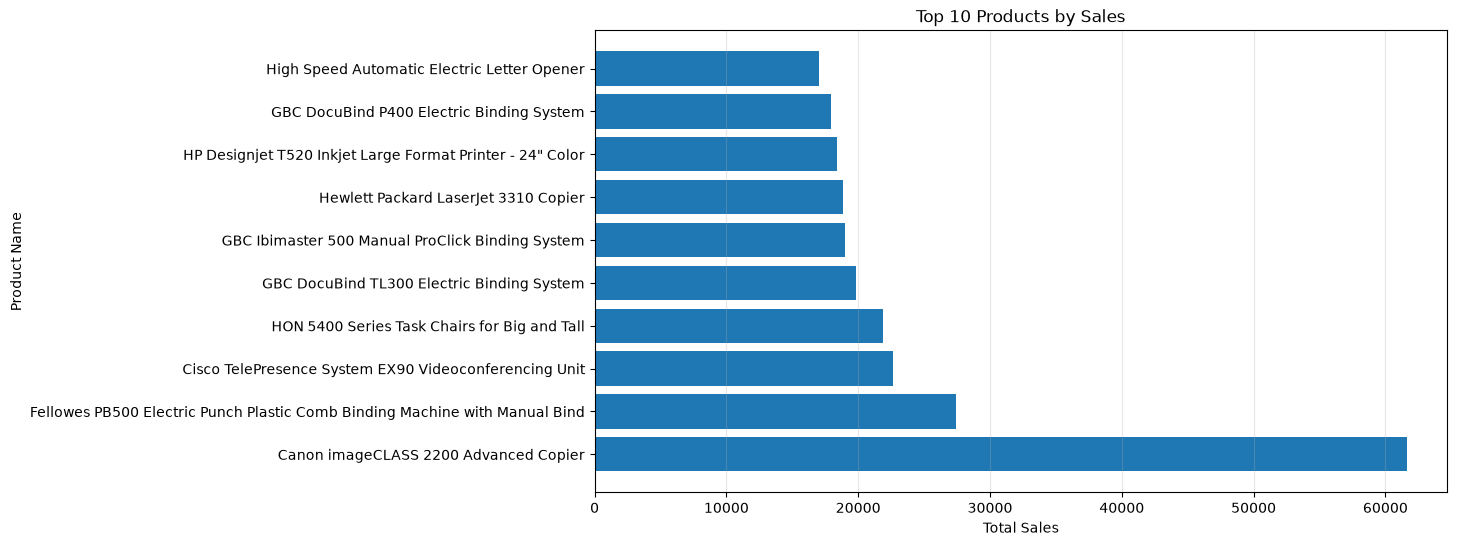

In [73]:
plt.figure(figsize=(11, 6))

plt.barh(top_10_products.index, top_10_products.values)

plt.title('Top 10 Products by Sales')
plt.xlabel('Total Sales')
plt.ylabel('Product Name')

plt.grid(axis='x', alpha=0.3)
plt.show()

In [74]:
top_10_customers = customer_sales.sort_values(ascending=False).head(10)
top_10_customers

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64

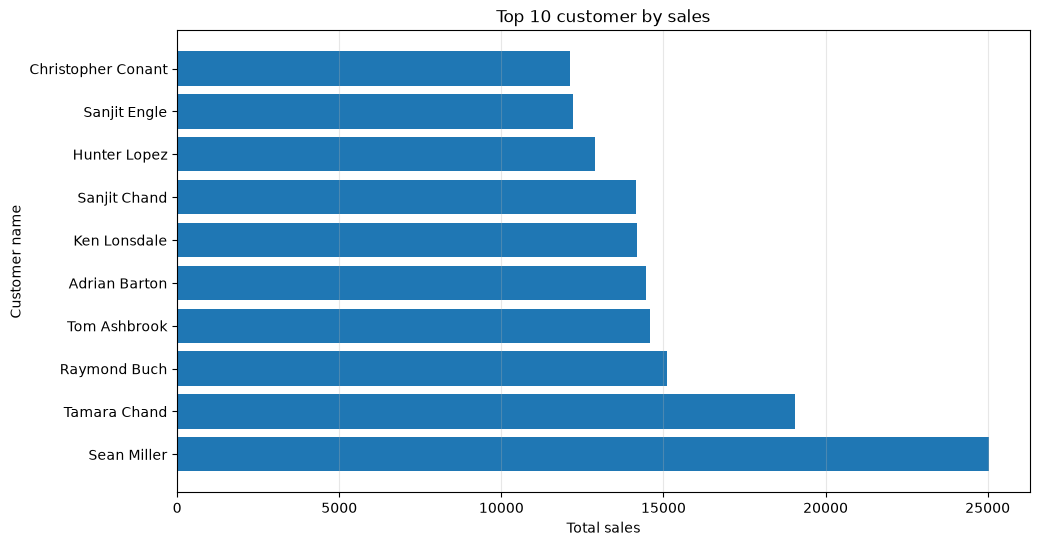

In [75]:
plt.figure(figsize=(11,6))

plt.barh(top_10_customers.index,top_10_customers.values)
plt.title('Top 10 customer by sales')
plt.xlabel('Total sales')
plt.ylabel('Customer name')

plt.grid(axis='x',alpha=0.3)
plt.show()

In [76]:
profit_status_count = df_clean['Profit'].value_counts()
profit_status_count

Profit
0.0000     65
6.2208     43
9.3312     39
5.4432     32
3.6288     32
           ..
12.1176     1
56.5110     1
19.7910     1
6.4750      1
2.7279      1
Name: count, Length: 7597, dtype: int64

In [78]:
sales_array = df_clean['Sales'].to_numpy()
profit_array = df_clean['Profit'].to_numpy()


In [83]:
type(sales_array),type(profit_array)

(numpy.ndarray, numpy.ndarray)

In [84]:
sales_mean = np.mean(sales_array)
profit_mean = np.mean(profit_array)

print('Average sale :',sales_mean)
print('Average profit :',profit_mean)

Average sale : 228.22585386501862
Average profit : 28.67341716696095


In [85]:
sales_median = np.median(sales_array)
profit_median = np.median(profit_array)

print('Median sales :',sales_median)
print('Median profit :',profit_median)

Median sales : 53.91
Median profit : 8.69


In [86]:
sales_std = np.std(sales_array)
profit_std = np.std(profit_array)

print("Sales Standard Deviation:", sales_std)
print("Profit Standard Deviation:", profit_std)

Sales Standard Deviation: 619.8764325578662
Profit Standard Deviation: 232.45371272111188


In [87]:
statistics_summary = {
    'Sales': [sales_mean, sales_median, sales_std],
    'Profit': [profit_mean, profit_median, profit_std]
}

statistics_summary

{'Sales': [np.float64(228.22585386501862),
  np.float64(53.91),
  np.float64(619.8764325578662)],
 'Profit': [np.float64(28.67341716696095),
  np.float64(8.69),
  np.float64(232.45371272111188)]}

In [88]:
yearly_analysis

,Sales,Profit,Profit margin
Order Year,,,
2023,494040.2121,51684.2957,10.461556
2024,472993.0310,62020.9695,13.112449
2025,613933.5800,82665.2018,13.464844
2026,745567.5312,95926.3476,12.866218


In [89]:
monthly_analysis.sort_values('Sales', ascending=False)

,Sales,Profit
Month Name,,
November,352665.9910,35541.2553
December,330218.1755,44229.8480
September,308883.6697,37234.5608
March,210672.0868,29345.0405
October,207126.2567,33214.5143
August,161821.9150,22942.4239
May,158765.0337,22850.0324
June,153459.9973,21508.2067
July,149001.7130,14013.5496



# Retail Sales & Business Performance Analysis

**Tools & Libraries:** Python, NumPy, Pandas, Matplotlib

## 1. Project Introduction

This project focuses on analyzing retail sales data to understand business performance, sales trends, customer behavior, and profitability.

The analysis uses Python libraries to clean, process, analyze, and visualize the dataset.

## Project Objectives

- Analyze overall sales and profit performance.
- Identify top-performing categories and products.
- Analyze customer and regional performance.
- Understand monthly and yearly sales trends.
- Identify loss-making products and categories.
- Generate meaningful business insights and recommendations.



## 2. Dataset Overview

The dataset used in this project is the Sample Superstore dataset.

It contains retail transaction records, including customer details, product information, sales, quantity, discounts, and profit.

### Dataset Information

- **Dataset Name:** Sample Superstore
- **Total Records:** 10,194
- **Original Columns:** 21
- **Categories:** Furniture, Office Supplies, Technology
- **Regions:** Central, East, South, West

### Important Columns

| Column | Description |
|---|---|
| Order ID | Unique order identifier |
| Order Date | Date when order was placed |
| Customer Name | Customer name |
| Category | Product category |
| Sub-Category | Product sub-category |
| Sales | Sales amount |
| Quantity | Number of items |
| Discount | Discount applied |
| Profit | Profit or loss |




## 3. Data Inspection & Cleaning

The dataset was inspected to understand its structure, data types, missing values, duplicate records, and data quality.

### Inspection Performed

- Checked the first few records using `head()`.
- Checked dataset dimensions using `shape`.
- Reviewed column names and data types.
- Analyzed numerical columns using `describe()`.
- Checked missing values and duplicate records.
- Verified date columns and invalid shipping dates.
- Checked text columns for unnecessary whitespace.

### Data Quality Findings

- Total records: 10,194
- Missing values: 0
- Duplicate records: 0
- Unnecessary whitespace: Not found
- Order Date and Ship Date were already in datetime format.
- Postal Code was retained as an identifier.

### Important Observation

The dataset contains 611 future-dated orders between November 21, 2026 and December 30, 2026.

These records were retained because there was no evidence that they were invalid.



## 4. Data Preparation & Feature Engineering

A working copy of the original dataset was created to perform data preparation and feature engineering.

### New Columns Created

| Column | Purpose |
|---|---|
| Order Year | Extracted year from Order Date |
| Order Month | Extracted month number |
| Month Name | Extracted month name |
| Shipping Days | Calculated shipping duration |
| Profit margin | Calculated profit margin |
| Profit Status | Classified records as Profitable, Loss, or Break-even |

### Feature Engineering Details

- Calculated shipping duration using Order Date and Ship Date.
- Calculated profit margin as a percentage of sales.
- Classified each record based on its profit value.
- Used NumPy operations for conditional classification.

These additional columns helped perform detailed business analysis.



## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to identify important patterns, trends, and relationships in the retail dataset.

### 5.1 Category Analysis
- Analyzed total Sales, Profit, Quantity, and Average Discount by Category.
- Compared the performance of Furniture, Office Supplies, and Technology.

### 5.2 Region Analysis
- Compared Sales and Profit across four regions.
- Identified the highest and lowest performing regions.

### 5.3 Sub-Category Analysis
- Identified the top-performing and loss-making sub-categories.
- Compared profitability across different sub-categories.

### 5.4 Product Analysis
- Identified the top 10 products by Sales.
- Identified the top 10 products by Profit.
- Analyzed loss-making products.

### 5.5 Customer Analysis
- Identified top customers by Sales and Profit.
- Analyzed customers generating negative profit.

### 5.6 Time-Based Analysis
- Analyzed yearly Sales and Profit.
- Analyzed monthly Sales and Profit.
- Calculated yearly Profit Margin.
- Identified high and low performing months.



## 6. Data Visualization

Matplotlib was used to create visualizations to understand business performance and communicate analytical findings.

### Visualizations Created

1. Year-wise Sales Analysis – Bar Chart
2. Year-wise Profit Analysis – Bar Chart
3. Monthly Sales Trend – Line Chart
4. Monthly Profit Trend – Line Chart
5. Category-wise Sales Analysis – Bar Chart
6. Category-wise Profit Analysis – Bar Chart
7. Region-wise Sales Analysis – Bar Chart
8. Region-wise Profit Analysis – Bar Chart
9. Top 10 Sub-Categories by Profit – Horizontal Bar Chart
10. Top 10 Products by Sales – Horizontal Bar Chart
11. Top 10 Customers by Sales – Horizontal Bar Chart

These visualizations helped identify sales trends, profitability patterns, and top-performing business segments.



## 7. NumPy Statistical Analysis

NumPy was used to perform statistical calculations on Sales and Profit data.

### Statistical Measures

1. **Mean:** Calculated the average Sales and Profit.
2. **Median:** Identified the middle value of Sales and Profit.
3. **Standard Deviation:** Measured the variation in Sales and Profit values.

### Results

| Statistical Measure | Sales | Profit |
|---|---:|---:|
| Mean | 228.23 | 28.67 |
| Median | 53.91 | 8.69 |
| Standard Deviation | 619.88 | 232.45 |

The difference between Mean and Median indicates that some high-value transactions influence the average values.



## 8. Business Insights & Recommendations

Based on the analysis, the following business insights and recommendations were identified.

### 1. Category Performance
- Technology generated the highest Sales and Profit.
- Furniture generated good Sales but comparatively low Profit.
- **Recommendation:** Review Furniture pricing, costs, and discount strategies.

### 2. Regional Performance
- West was the best-performing region in terms of Sales and Profit.
- South recorded the lowest Sales.
- **Recommendation:** Focus on improving sales performance in the South region.

### 3. Sub-Category Performance
- Copiers generated the highest Profit.
- Tables recorded the highest loss.
- **Recommendation:** Review pricing, costs, and discounts for loss-making sub-categories.

### 4. Product Performance
- Canon imageCLASS 2200 Advanced Copier ranked first in both Sales and Profit.
- **Recommendation:** Maintain sufficient inventory based on product demand.

### 5. Loss-Making Products
- 302 products (16.33%) generated negative Profit.
- **Recommendation:** Review loss-making products and maintain inventory according to demand.

### 6. Customer Performance
- 158 customers (19.75%) generated negative Profit.
- **Recommendation:** Introduce targeted offers and profitable pricing strategies to improve customer profitability.

### 7. Yearly Performance
- 2026 recorded the highest Sales and Profit in the dataset.
- 2025 recorded the highest Profit Margin.
- **Recommendation:** Study the profitable strategies used in 2025 and focus on improving margins.

### 8. Monthly Performance
- November recorded the highest Sales.
- December recorded the highest Profit.
- **Recommendation:** Plan inventory and promotions according to monthly demand patterns.



## 9. Project Conclusion

This project analyzed retail sales data using Python, NumPy, Pandas, and Matplotlib.

The analysis covered sales trends, product performance, customer behavior, regional performance, and profitability.

Key findings included Technology as the highest-performing category, West as the leading region, and Tables as the most loss-making sub-category.

Statistical analysis helped understand the distribution and variation of Sales and Profit.

The project also identified opportunities to improve profitability through better pricing, inventory management, and customer-focused strategies.

Overall, this project provided practical experience in data cleaning, exploratory data analysis, statistical analysis, data visualization, and business decision-making using Python.
